# Level 3, Task 1: Time Series Analysis
**Codveda Technology | Data Science Internship**

**Summary of Tasks**

In this notebook I analysed a time series and forecasted it. I used the classic monthly airline passengers data (1949 to 1960). I ploted the series and decomposed it into trend, seasonality and residual, applied moving averages and exponential smoothing, and built a SARIMA model. I evaluated every model on the last 24 months with RMSE, compared them against a simple baseline, and finally ploted a forecast for the next 24 months.

**About the data:** the file `airline_passengers.csv` holds the monthly number of international airline passengers, in thousands, for 144 months. This is the well-known Box and Jenkins airline series. I downloaded it from the example-data repository of the seaborn library on GitHub (`mwaskom/seaborn-data`). I chose it because none of the files I was given has a regular date column, and this series has a clear trend and yearly pattern, so every method in the task has something to show.

## 1.0 Setting Up

### 1.1 Importing the Libraries

In [3]:
import pandas as pd                                    # tables and dates
import numpy as np                                     # logs, square roots and other maths
import matplotlib.pyplot as plt                        # base plotting
import seaborn as sns                                  # month-by-month box plot
import warnings                                        # to keep the model-fitting output tidy
from statsmodels.tsa.seasonal import seasonal_decompose                        # split a series into trend, seasonality, residual
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing   # exponential smoothing models
from statsmodels.tsa.statespace.sarimax import SARIMAX                         # the SARIMA model
from statsmodels.tsa.stattools import adfuller                                 # stationarity test
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf                  # autocorrelation plots
from statsmodels.stats.diagnostic import acorr_ljungbox                        # check the model residuals
from sklearn.metrics import mean_squared_error, mean_absolute_error            # error metrics

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")      # statsmodels prints many harmless warnings while fitting

**Interpretation:** All the libraries loaded. Besides pandas and the plotting tools, I used statsmodels for the time series methods (decomposition, exponential smoothing, SARIMA and the statistical tests) and scikit-learn for the error metrics. I turned off the warnings only to keep the output readable, because statsmodels prints many harmless messages while fitting.

### 1.2 Loading the Dataset

In [4]:
DATA_PATH = "airline_passengers.csv"    
raw = pd.read_csv(DATA_PATH)

print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (144, 3)


,year,month,passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


**Interpretation:** The file has 144 rows, one per month, with three columns: the year, the month name and the number of passengers (in thousands). Python does not yet understand these as dates, so I fixed that next.

### 1.3 Building a Proper Date Index

In [6]:
# the file has a year and a month name, so I combine them into one real date
raw["date"] = pd.to_datetime(raw["year"].astype(str) + "-" + raw["month"], format="%Y-%B")
ts = raw.set_index("date")["passengers"].asfreq("MS")    # MS = one observation at the start of every month

print("From", ts.index.min().date(), "to", ts.index.max().date(), "| observations:", len(ts))
print("Missing values:", ts.isnull().sum())
ts.head()

From 1949-01-01 to 1960-12-01 | observations: 144
Missing values: 0


date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

**Interpretation:** I combined the year and month into a real date and used it as the index. The series runs from January 1949 to December 1960 with 144 monthly observations and no missing values. Setting the frequency to month start (`MS`) tells statsmodels that the data is regular, one value per month, which the time series models need.

## 2.0 Exploring the Series

### 2.1 Plotting the Series

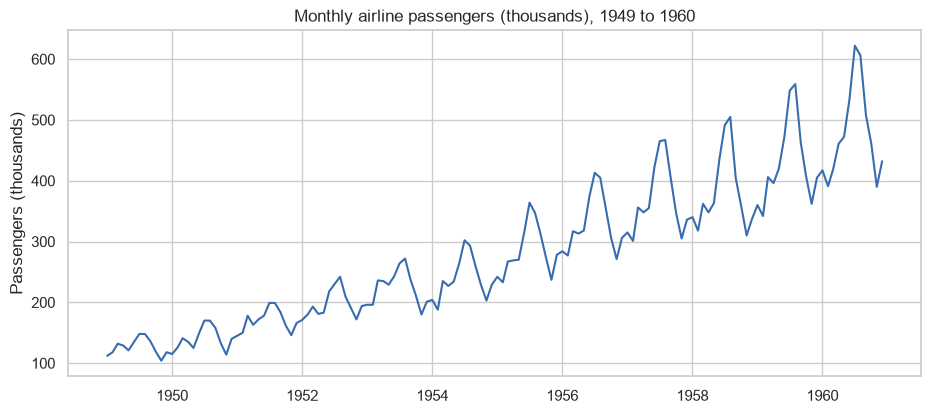

count    144.0
mean     280.3
std      120.0
min      104.0
25%      180.0
50%      265.5
75%      360.5
max      622.0
Name: passengers, dtype: float64


In [7]:
plt.figure(figsize=(11, 4.5))
plt.plot(ts, color="#386cb0")
plt.title("Monthly airline passengers (thousands), 1949 to 1960")
plt.ylabel("Passengers (thousands)")
plt.show()

print(ts.describe().round(1))

**Interpretation:** The number of passengers rises strongly over the years, from around 100 thousand a month in 1949 to over 600 thousand in 1960 (the average is 280.3 thousand). There is also a repeating up-and-down pattern inside each year, and the ups and downs get larger as the numbers grow. These are the three things I need to handle: a trend, a yearly seasonal pattern, and seasonal swings that grow with the level.

### 2.2 Yearly Growth and Monthly Pattern

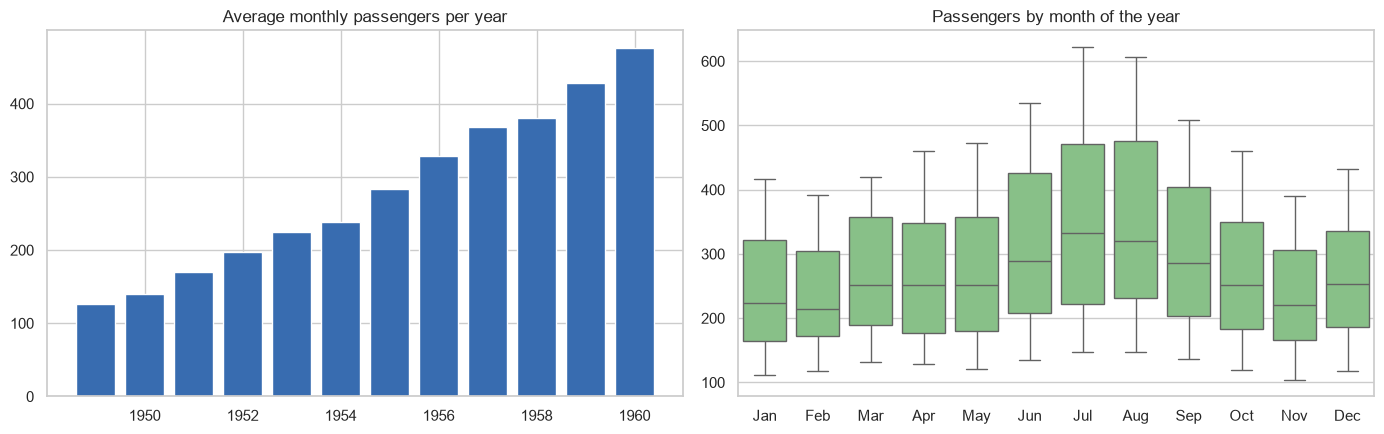

Average growth from 1949 to 1960: 276%
{'Jan': 242.0, 'Feb': 235.0, 'Mar': 270.0, 'Apr': 267.0, 'May': 272.0, 'Jun': 312.0, 'Jul': 351.0, 'Aug': 351.0, 'Sep': 302.0, 'Oct': 267.0, 'Nov': 233.0, 'Dec': 262.0}


In [8]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

yearly = ts.groupby(ts.index.year).mean()
axes[0].bar(yearly.index, yearly.values, color="#386cb0")
axes[0].set_title("Average monthly passengers per year")

sns.boxplot(x=ts.index.strftime("%b"), y=ts.values, order=months, ax=axes[1], color="#7fc97f")
axes[1].set_title("Passengers by month of the year")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

print("Average growth from 1949 to 1960: %.0f%%" % ((yearly.iloc[-1] / yearly.iloc[0] - 1) * 100))
print(ts.groupby(ts.index.strftime("%b")).mean().reindex(months).round(0).to_dict())

**Interpretation:** The left chart confirms the growth: the average number of monthly passengers rose every year, and by 1960 it was 276% higher than in 1949. The right chart shows the monthly pattern. July and August are the busiest months (an average of about 351 thousand), and the quietest are November (233), February (235) and January (242). So the yearly cycle peaks in the summer and dips in the autumn and winter.

## 3.0 Decomposition into Trend, Seasonality and Residual

### 3.1 Choosing Between an Additive and a Multiplicative Model

In [9]:
# if the seasonal swing grows together with the level, a multiplicative model is the right choice
yearly = ts.groupby(ts.index.year).agg(["mean", "min", "max"])
yearly["swing (max - min)"] = yearly["max"] - yearly["min"]
yearly["swing as % of average"] = yearly["swing (max - min)"] / yearly["mean"] * 100
yearly.round(0).astype(int)

,mean,min,max,swing (max - min),swing as % of average
date,,,,,
1949,127,104,148,44,35
1950,140,114,170,56,40
1951,170,145,199,54,32
1952,197,171,242,71,36
1953,225,180,272,92,41
1954,239,188,302,114,48
1955,284,233,364,131,46
1956,328,271,413,142,43
1957,368,301,467,166,45


**Interpretation:** In 1949 the gap between the busiest and quietest month was 44 thousand passengers, and by 1960 it had grown to 232 thousand, more than five times larger. As a share of the yearly average, though, the swing stays in a similar range (between about 32% and 51%). This means the seasonal pattern grows in proportion to the level of the series, so I use a **multiplicative** decomposition, where the components are multiplied together rather than added.

### 3.2 The Decomposition

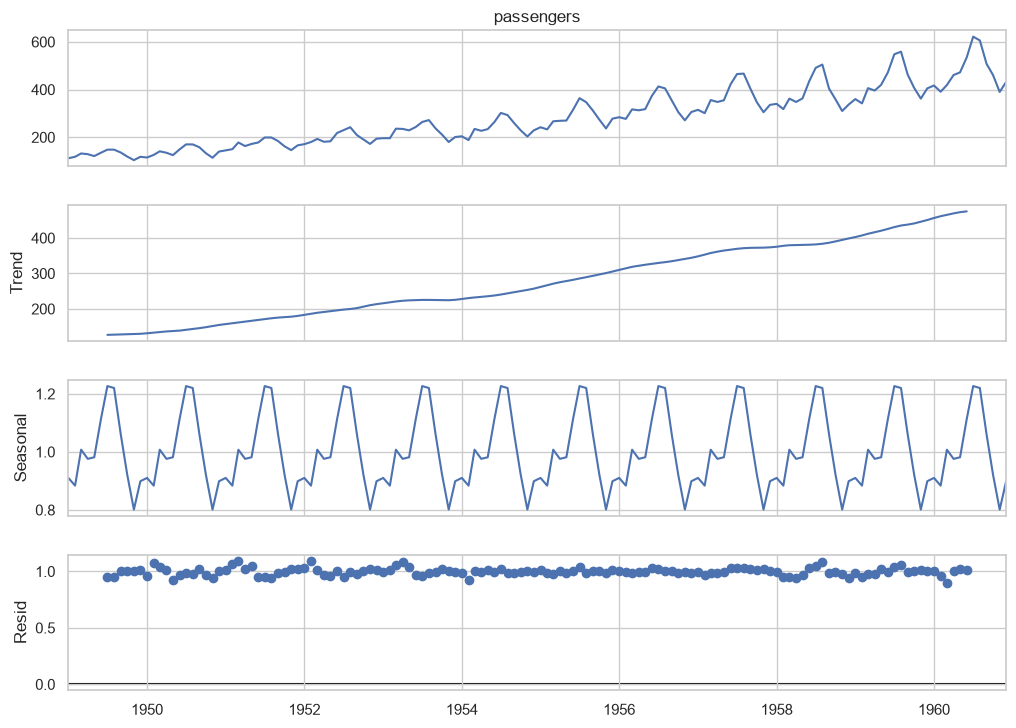

In [10]:
mul = seasonal_decompose(ts, model="multiplicative", period=12)    # period=12 because the pattern repeats every 12 months

fig = mul.plot()
fig.set_size_inches(11, 8)
plt.show()

**Interpretation:** The decomposition splits the series into three parts. The **trend** rises steadily the whole time. The **seasonal** part repeats the same shape every year, as multipliers around 1 (above 1 means busier than the trend, below 1 quieter). The **residual** is what is left over, and it stays close to 1 (mostly between about 0.9 and 1.1) with no obvious pattern, so the trend and seasonality explain nearly everything. The trend line stops about six months before each end, because it is calculated with a window that needs data on both sides.

### 3.3 Reading the Seasonal Pattern

In [11]:
seasonal_factors = mul.seasonal[:12]
seasonal_factors.index = months
print(seasonal_factors.round(3))

print("\nTrend at the start:", round(mul.trend.dropna().iloc[0], 1), "| trend at the end:", round(mul.trend.dropna().iloc[-1], 1))

Jan    0.910
Feb    0.884
Mar    1.007
Apr    0.976
May    0.981
Jun    1.113
Jul    1.227
Aug    1.220
Sep    1.060
Oct    0.922
Nov    0.801
Dec    0.899
Name: seasonal, dtype: float64

Trend at the start: 126.8 | trend at the end: 475.0


**Interpretation:** The seasonal factors give the yearly pattern in numbers. July (1.227) and August (1.220) are about 22% to 23% above the trend level, while November (0.801) is about 20% below it. The trend itself grows from about 127 thousand at the start to about 475 thousand at the end.

## 4.0 Moving Averages

### 4.1 Smoothing the Series

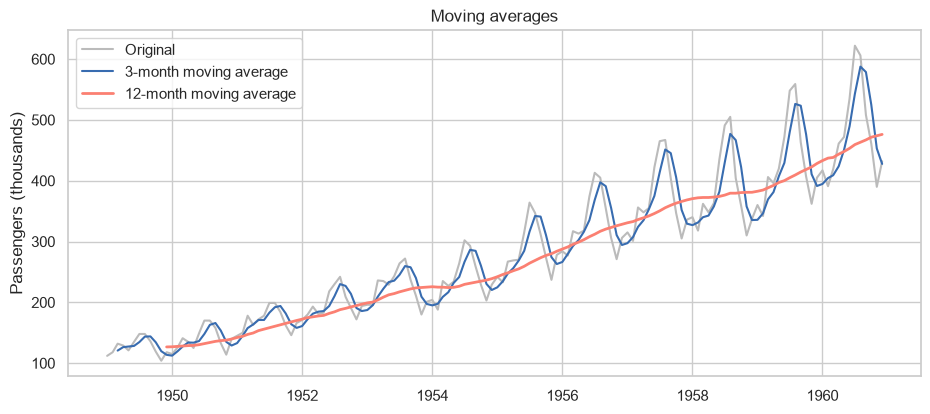

In [12]:
ma3 = ts.rolling(window=3).mean()
ma12 = ts.rolling(window=12).mean()

plt.figure(figsize=(11, 4.5))
plt.plot(ts, label="Original", color="#bbbbbb")
plt.plot(ma3, label="3-month moving average", color="#386cb0")
plt.plot(ma12, label="12-month moving average", color="#fb8072", lw=2)
plt.title("Moving averages")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

**Interpretation:** The 3-month moving average smooths the small month-to-month jumps but still shows the yearly ups and downs. The 12-month moving average averages over exactly one full cycle, so the seasonal pattern cancels out and what remains is the smooth upward trend, which agrees with the trend from the decomposition. Both lines start later than the data (they need 3 or 12 months to fill their windows) and they lag behind the series at turning points, because each average only looks backwards.

## 5.0 Train/Test Split and a Baseline

### 5.1 Keeping the Last 24 Months for Testing

In [13]:
# with time series I cannot split randomly: the test set must come after the training set
train = ts[:-24]
test = ts[-24:]

print("Training:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} months)")
print("Testing :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} months)")

Training: 1949-01-01 to 1958-12-01 (120 months)
Testing : 1959-01-01 to 1960-12-01 (24 months)


**Interpretation:** I trained on the first 120 months (1949 to 1958) and kept the last 24 months (1959 and 1960) for testing. For time series the split cannot be random, because a model must predict the future from the past, so the test months always come after the training months.

### 5.2 A Simple Baseline: Repeat Last Year

In [14]:
def score(actual, forecast):
    mse = mean_squared_error(actual, forecast)
    return {"RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(actual, forecast),
            "MAPE (%)": np.mean(np.abs((actual - forecast) / actual)) * 100}

# forecast every future month with the value from the same month in the last year of training
naive_fc = pd.Series(np.tile(train.values[-12:], 2), index=test.index)

pd.DataFrame({"Seasonal naive": score(test.values, naive_fc.values)}).T.round(2)

,RMSE,MAE,MAPE (%)
Seasonal naive,76.99,71.25,15.52


**Interpretation:** Before building clever models, I set a simple baseline: predict every month with the value from the same month in the last training year. It gets an RMSE of 76.99 (a typical error of about 77 thousand passengers) and a MAPE of 15.5%. RMSE is the square root of the average squared error, MAE is the average size of the error, and MAPE is the average error as a percentage of the real value. Any model I build should beat this baseline, or it is not adding anything. The baseline does badly because the series keeps growing, so last year's values are always too low.

## 6.0 Exponential Smoothing

### 6.1 Simple Exponential Smoothing

In [15]:
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
ses_fc = ses.forecast(24)

print("Smoothing level (alpha):", round(ses.params["smoothing_level"], 3))
pd.DataFrame({"Simple exponential smoothing": score(test.values, ses_fc.values)}).T.round(2)

Smoothing level (alpha): 1.0


,RMSE,MAE,MAPE (%)
Simple exponential smoothing,137.33,115.25,23.58


**Interpretation:** Simple exponential smoothing chose a smoothing level of 1.0, which means it simply repeats the last value it saw. The forecast is therefore a flat line. It does very badly (RMSE 137.33, MAPE 23.6%), even worse than the baseline, because this method has no way to represent a trend or a seasonal pattern.

### 6.2 Holt-Winters (Trend and Seasonality)

In [16]:
hw = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12,
                          initialization_method="estimated").fit()
hw_fc = hw.forecast(24)

print("Smoothing level:", round(hw.params["smoothing_level"], 3),
      "| trend:", round(hw.params["smoothing_trend"], 3),
      "| seasonal:", round(hw.params["smoothing_seasonal"], 3))
pd.DataFrame({"Holt-Winters": score(test.values, hw_fc.values)}).T.round(2)

Smoothing level: 0.364 | trend: 0.0 | seasonal: 0.636


,RMSE,MAE,MAPE (%)
Holt-Winters,32.49,28.98,6.39


**Interpretation:** Holt-Winters adds both a trend and a seasonal pattern (multiplicative, as I found in 3.1), and it does far better: RMSE 32.49, MAE 28.98 and MAPE 6.4%. The smoothing values show how it works. A level value of 0.364 and a seasonal value of 0.636 mean it keeps updating the level and the seasonal pattern as new data arrives. The trend value of 0.0 means the slope is not updated and keeps the value estimated from the start of the training data.

### 6.3 Comparing the Smoothing Forecasts with the Actual Values

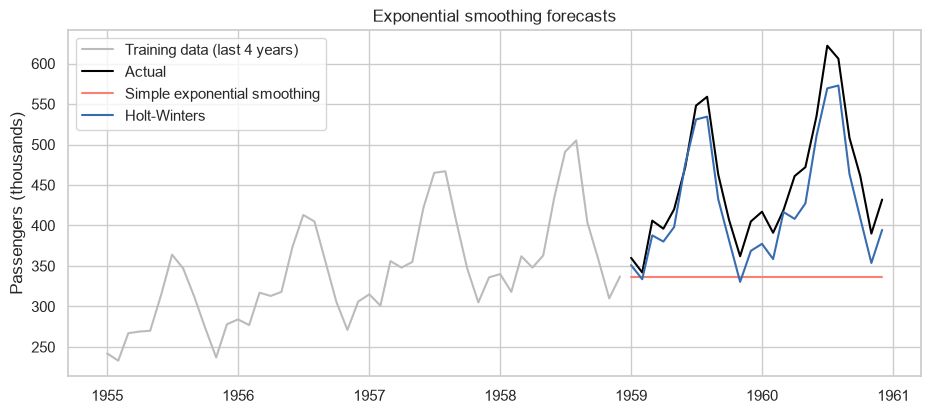

In [17]:
plt.figure(figsize=(11, 4.5))
plt.plot(train[-48:], color="#bbbbbb", label="Training data (last 4 years)")
plt.plot(test, color="black", label="Actual")
plt.plot(ses_fc, color="#fb8072", label="Simple exponential smoothing")
plt.plot(hw_fc, color="#386cb0", label="Holt-Winters")
plt.title("Exponential smoothing forecasts")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

**Interpretation:** The flat red line is simple exponential smoothing and clearly misses everything. The green Holt-Winters line follows the rises and falls of the actual values closely, although it stays a little below the real values at the summer peaks.

## 7.0 SARIMA Model

### 7.1 Making the Series Stationary

In [18]:
log_train = np.log(train)      # a log turns the growing seasonal swings into a steady size

def adf_row(series, name):
    stat, p = adfuller(series.dropna())[:2]
    return {"Series": name, "ADF statistic": stat, "p-value": p}

pd.DataFrame([
    adf_row(train, "Original"),
    adf_row(log_train, "Log"),
    adf_row(log_train.diff(), "Log, differenced once"),
    adf_row(log_train.diff().diff(12), "Log, differenced once + seasonal difference"),
]).set_index("Series").round(4)

,ADF statistic,p-value
Series,,
Original,-0.7735,0.8268
Log,-1.9246,0.3206
"Log, differenced once",-2.3432,0.1584
"Log, differenced once + seasonal difference",-4.0046,0.0014


**Interpretation:** The test asks whether a series is stationary (its average and spread do not change over time). Here a small p-value (below 0.05) means it is. The original series (p = 0.83), the log series (p = 0.32) and the log series differenced once (p = 0.16) are all not stationary. Only after I also take a seasonal difference (subtracting the value from 12 months earlier) does it become stationary (p = 0.0014). The log removes the growing size of the seasonal swings, one difference removes the trend, and the seasonal difference removes the yearly pattern. This tells me to use d = 1 and D = 1 in the model.

### 7.2 Autocorrelation Plots

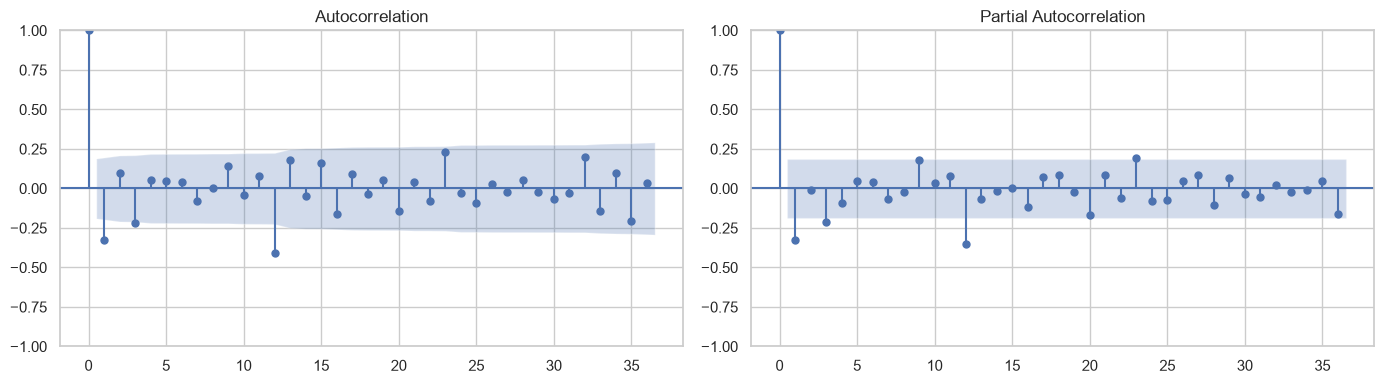

In [19]:
stationary = log_train.diff().diff(12).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(stationary, lags=36, ax=axes[0])
plot_pacf(stationary, lags=36, ax=axes[1], method="ywm")
plt.tight_layout()
plt.show()

**Interpretation:** These charts help choose the model terms. The autocorrelation chart (left) has clear negative spikes at lag 1 and at lag 12, which points to one regular moving-average term and one seasonal moving-average term. That is the pattern behind the well-known (0,1,1)(0,1,1,12) structure for this kind of data. The partial autocorrelation chart (right) is less clean, so rather than rely on eye-reading alone, I compare many models in the next step.

### 7.3 Searching for the Best Orders

In [20]:
# I try a small grid of models and compare them with the AIC (lower is better)
results = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                try:
                    m = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
                    results.append({"order (p,d,q)": (p, 1, q), "seasonal (P,D,Q,s)": (P, 1, Q, 12), "AIC": m.aic})
                except Exception:
                    pass

search = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
print("Models tried:", len(search))
search.head(5).round(1)

Models tried: 36


,"order (p,d,q)","seasonal (P,D,Q,s)",AIC
0,"(0, 1, 1)","(0, 1, 1, 12)",-389.0
1,"(1, 1, 0)","(0, 1, 1, 12)",-388.6
2,"(1, 1, 1)","(0, 1, 1, 12)",-387.3
3,"(0, 1, 1)","(1, 1, 1, 12)",-387.2
4,"(0, 1, 2)","(0, 1, 1, 12)",-387.1


**Interpretation:** I fitted 36 combinations of orders and ranked them by AIC, which rewards a good fit but penalises extra complexity (lower is better). I use the training data only for this, so the choice does not depend on the test period. The best model is SARIMA(0,1,1)(0,1,1,12) with an AIC of -389.0. The second best (-388.6) is very close, because AIC differences under about 2 are not meaningful, and all of the top five contain the seasonal moving-average term, which agrees with the autocorrelation chart.

### 7.4 Fitting the Best Model

In [21]:
best_order = search.loc[0, "order (p,d,q)"]
best_seasonal = search.loc[0, "seasonal (P,D,Q,s)"]

sarima = SARIMAX(log_train, order=best_order, seasonal_order=best_seasonal).fit(disp=False)

print("Chosen model: SARIMA", best_order, best_seasonal)
print(sarima.summary().tables[1])

Chosen model: SARIMA (0, 1, 1) (0, 1, 1, 12)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3427      0.087     -3.924      0.000      -0.514      -0.172
ma.S.L12      -0.5407      0.105     -5.156      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.864      0.000       0.001       0.002


**Interpretation:** Both model terms are statistically significant (p-values of 0.000). The regular moving-average term (-0.34) and the seasonal one (-0.54) mean that each forecast is corrected using last month's error and the error from the same month a year ago. The model is fitted on the log of the passengers, so I convert its forecasts back with the exponential function later.

### 7.5 Checking the Residuals

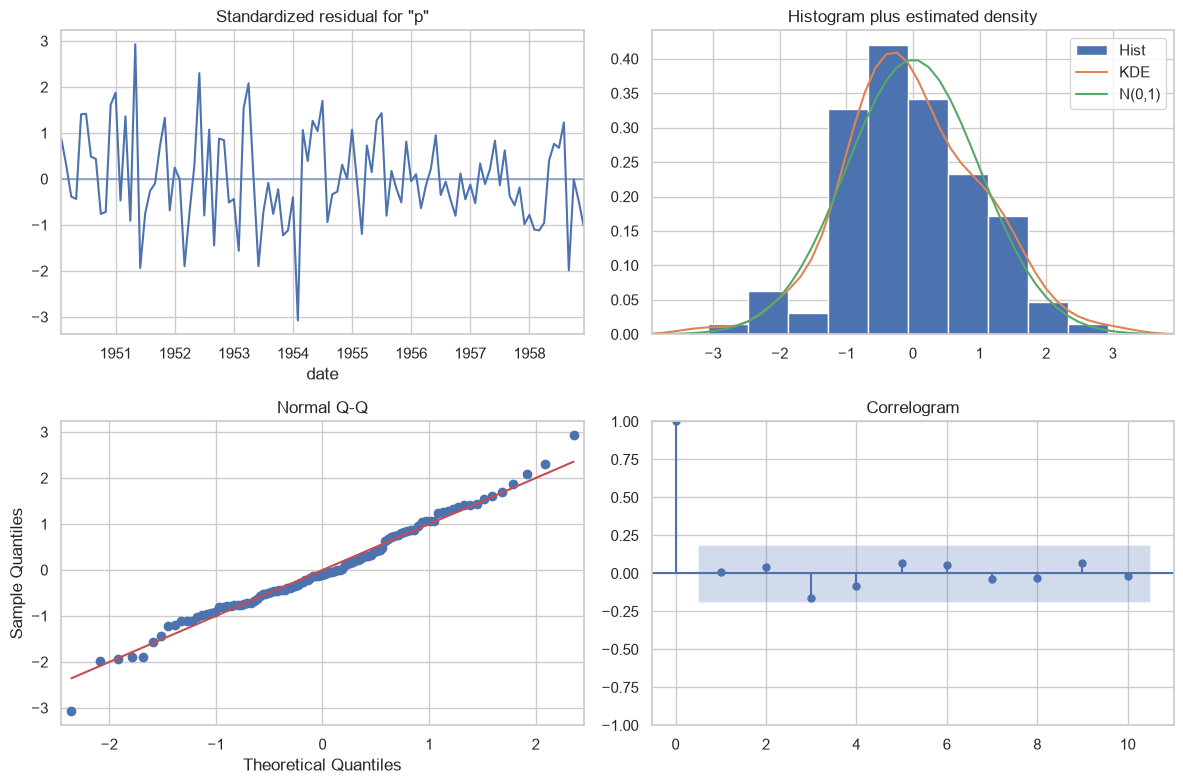

,lb_stat,lb_pvalue
12,6.071,0.912
24,17.983,0.804


In [22]:
sarima.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

# skip the first 13 residuals, which are distorted by the differencing
acorr_ljungbox(sarima.resid[13:], lags=[12, 24], return_df=True).round(3)

**Interpretation:** The residuals should look like random noise if the model has captured the pattern. The residual plot hovers around zero with no trend, the histogram is close to a bell shape, the Q-Q plot follows the line apart from a few points at the ends, and the correlogram stays inside the blue band. The Ljung-Box test agrees: its p-values are 0.91 (12 lags) and 0.80 (24 lags), both well above 0.05, so there is no leftover pattern for the model to learn.

### 7.6 Forecasting the Test Period

         RMSE    MAE  MAPE (%)
SARIMA  43.17  39.43      8.51


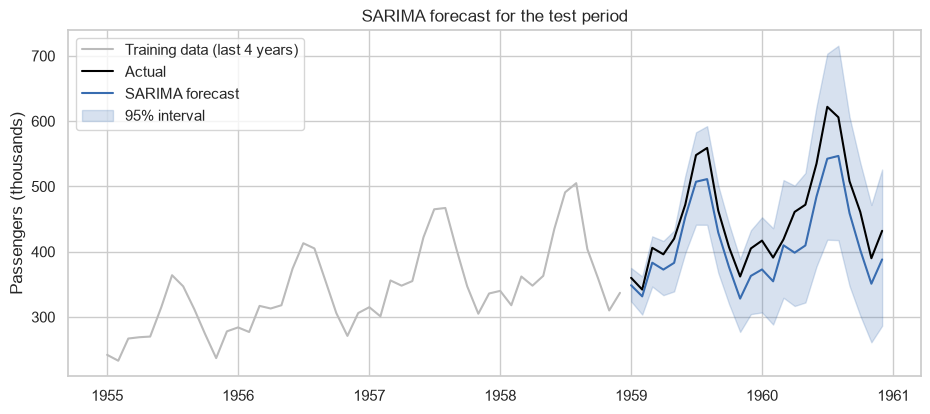

In [23]:
fc = sarima.get_forecast(steps=24)
sarima_fc = np.exp(fc.predicted_mean)       # back from the log scale to passengers
ci = np.exp(fc.conf_int())                  # 95% prediction interval

assert (sarima_fc.index == test.index).all()
print(pd.DataFrame({"SARIMA": score(test.values, sarima_fc.values)}).T.round(2))

plt.figure(figsize=(11, 4.5))
plt.plot(train[-48:], color="#bbbbbb", label="Training data (last 4 years)")
plt.plot(test, color="black", label="Actual")
plt.plot(sarima_fc, color="#386cb0", label="SARIMA forecast")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#386cb0", alpha=0.2, label="95% interval")
plt.title("SARIMA forecast for the test period")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

**Interpretation:** On the test period the SARIMA model gets an RMSE of 43.17, an MAE of 39.44 and a MAPE of 8.5%. It follows the seasonal shape well, and the real values stay inside the 95% interval throughout. However, the forecast sits below the real values in every one of the 24 months, and the gap is largest at the summer peaks of 1960. The passenger numbers grew faster in 1959 and 1960 than the model extrapolated from the earlier years.

## 8.0 Comparing All the Models

### 8.1 Error Metrics

In [25]:
all_fc = {"Seasonal naive (baseline)": naive_fc,
          "Simple exponential smoothing": ses_fc,
          "Holt-Winters": hw_fc,
          "SARIMA": sarima_fc}

comparison = pd.DataFrame({name: score(test.values, f.values) for name, f in all_fc.items()}).T
comparison.sort_values("RMSE").round(2)

,RMSE,MAE,MAPE (%)
Holt-Winters,32.49,28.98,6.39
SARIMA,43.17,39.43,8.51
Seasonal naive (baseline),76.99,71.25,15.52
Simple exponential smoothing,137.33,115.25,23.58


**Interpretation:** Holt-Winters has the lowest error on this test period (RMSE 32.49, MAPE 6.4%), followed by SARIMA (43.17 and 8.5%). Both are far better than the baseline (76.99 and 15.5%): Holt-Winters cuts the RMSE by about 58%, and SARIMA by about 44%. Simple exponential smoothing is the worst (137.33). So adding a trend and a seasonal component is what matters most.

### 8.2 All Forecasts on One Chart

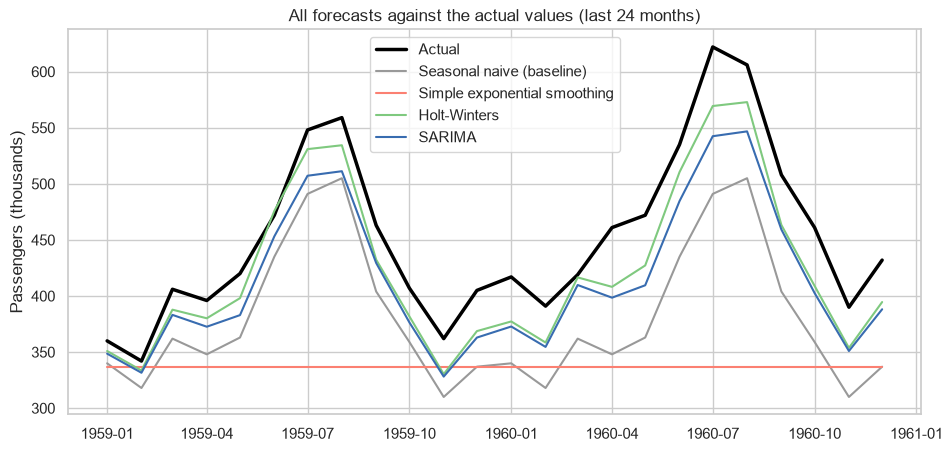

In [26]:
plt.figure(figsize=(11, 5))
plt.plot(test, color="black", lw=2.5, label="Actual")
for (name, f), colour in zip(all_fc.items(), ["#999999", "#fb8072", "#7fc97f", "#386cb0"]):
    plt.plot(f, label=name, color=colour)
plt.title("All forecasts against the actual values (last 24 months)")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

**Interpretation:** Both Holt-Winters (green) and SARIMA (blue) follow the shape of the real values (black), but both fall below them at the peaks of 1960, which is where most of their error comes from. The baseline copies last year and is always too low because of the growth, and the flat simple smoothing line ignores the pattern completely.

## 9.0 Forecasting the Future

### 9.1 Refitting on All the Data and Forecasting 24 Months Ahead

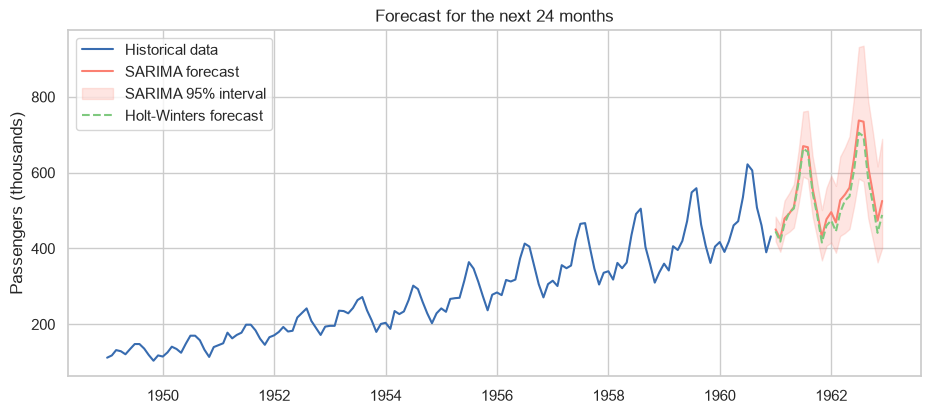

Average of the last real year (1960): 476.2
SARIMA, first and second forecast year      : 520.0 and 572.5
Holt-Winters, first and second forecast year: 511.0 and 543.2


In [27]:
final = SARIMAX(np.log(ts), order=best_order, seasonal_order=best_seasonal).fit(disp=False)

future = final.get_forecast(steps=24)
future_mean = np.exp(future.predicted_mean)
future_ci = np.exp(future.conf_int())

# Holt-Winters refitted on all the data, to see whether the two models agree
hw_final = ExponentialSmoothing(ts, trend="add", seasonal="mul", seasonal_periods=12,
                                initialization_method="estimated").fit()
hw_future = hw_final.forecast(24)

plt.figure(figsize=(11, 4.5))
plt.plot(ts, color="#386cb0", label="Historical data")
plt.plot(future_mean, color="#fb8072", label="SARIMA forecast")
plt.fill_between(future_ci.index, future_ci.iloc[:, 0], future_ci.iloc[:, 1], color="#fb8072", alpha=0.2, label="SARIMA 95% interval")
plt.plot(hw_future, color="#7fc97f", ls="--", label="Holt-Winters forecast")
plt.title("Forecast for the next 24 months")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

print("Average of the last real year (1960):", round(ts[-12:].mean(), 1))
print("SARIMA, first and second forecast year      :", round(future_mean[:12].mean(), 1), "and", round(future_mean[12:].mean(), 1))
print("Holt-Winters, first and second forecast year:", round(hw_future[:12].mean(), 1), "and", round(hw_future[12:].mean(), 1))

**Interpretation:** I refitted SARIMA on all 144 months and forecast the next 24 months (1961 and 1962). The forecast keeps the yearly pattern and continues the growth: the average for 1961 is about 520 thousand passengers a month, against 476 in 1960 (about 9% higher), and about 573 for 1962. Holt-Winters, shown as the dashed green line, agrees on the direction but is a little lower (511 and 543). The shaded band is the 95% interval for SARIMA, and it widens as I look further ahead, because the uncertainty builds up over time.

## 10.0 Conclusion

### 10.1 Results (Last 24 Months of Data)
| Model | RMSE | MAE | MAPE (%) |
|---|---|---|---|
| Seasonal naive (baseline) | 76.99 | 71.25 | 15.52 |
| Simple exponential smoothing | 137.33 | 115.25 | 23.58 |
| **Holt-Winters** | **32.49** | **28.98** | **6.39** |
| SARIMA (0,1,1)(0,1,1,12) | 43.17 | 39.44 | 8.51 |

### 10.2 What I Found
1. **The series has a strong trend and a yearly pattern.** The average monthly passengers grew by 276% between 1949 and 1960. July and August are the busiest months (about 22% to 23% above the trend), and November is the quietest (about 20% below).
2. **The seasonal swings grow with the level,** so a multiplicative model (or a log transformation) is the right choice.
3. **Models that ignore trend and seasonality fail.** Simple exponential smoothing was worse than the baseline.
4. **Holt-Winters was the most accurate on the test period,** with an RMSE of 32.49 and an error of about 6%. SARIMA was second (RMSE 43.17), and both beat the baseline by a wide margin.
5. **SARIMA is statistically sound.** Its residuals look like random noise (Ljung-Box p-values of 0.91 and 0.80), and it gives prediction intervals, which Holt-Winters does not.
6. **Both models forecast continued growth.** The average for 1961 is about 511 to 520 thousand passengers a month, against 476 in 1960.

### 10.3 Limitations
- I tested on only one 24-month window, so the ranking of Holt-Winters and SARIMA could change on a different window.
- Both models under-forecast the summer peaks of 1960, because growth sped up in the test period.
- The data covers 1949 to 1960 only, so the forecast for 1961 and 1962 is an exercise, not a real prediction.

### 10.4 Possible Next Steps
Test the models on several different windows (rolling evaluation) to see whether Holt-Winters stays ahead, try a damped trend, and repeat the analysis on a farm-related series such as monthly rainfall or crop prices.